In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

In [2]:
def split_levels(x):
    if ':' in x:
        l1, l2 = x.split(':', 1)
        return pd.Series([l1.strip(), l2.strip()])
    else:
        return pd.Series([x.strip(), None])

def two_level_barh(df, col, xlabel=None, ylabel=None):

    df[f"M_{col}"] = df[col].apply(lambda x: x.split(", "))

    exploded = df[f"M_{col}"].explode()
    exploded = exploded.apply(split_levels)
    exploded.columns = ['Level1', 'Level2']
    exploded['Level2'] = exploded['Level2'].fillna('Absent')

    counts = exploded.groupby(['Level1', 'Level2']).size().unstack(fill_value=0)
    totals = counts.sum(axis=1)
    counts = counts.loc[totals.sort_values(ascending=True).index]

    counts.plot(
        kind='barh',
        stacked=True,
    )
    if xlabel is not None:
        plt.xlabel(xlabel)
    if ylabel is not None:
        plt.ylabel(ylabel)

In [5]:
# read and process dataset

# path = r"data\src\conflated_database___2026_03_31__11_14_35.xlsx - TextReading_Included.csv"
# df = pd.read_csv(path, usecols={"topic": str, "Title": str, "Year": int, "Source": str})

path = r"data\src\conflated_database___2026_03_31__11_14_35.xlsx"

df = pd.read_excel(path, sheet_name="TextReading_Included")

df = df[df.topic.notna()]
df.reset_index(drop=True, inplace=True)

df.topic = df.topic.apply(lambda x: x.split(", "))
df.Year = df.Year.astype(int)
df

,topic,Detailed GP,Title,Year,Source,Unnamed: 5,Pre processing outside generative model,Core Generative Paradigm,Dataset,Unnamed: 9,...,Ultimate Output semantics,Generalizability,User Studies,AF: undefined,AF: similarity,AF: instruction-following,AF: Normative compliance,AF: Intrinsic,Compound Metrics,Ablation study (none if empty)
0,"[Model, Dataset, Evaluation]",Discriminators,Complex layout generation for large-scale floo...,2025,Scopus,NaN,Retriever: graph,Discriminative,"RPLAN, P-PLAN",NaN,...,space contour/function,Absent,Absent,"P accuracy, P error",Absent,Absent,Absent,"Quality: RAI, Quality: Space Property Proportion",Absent,yes
1,"[Model, Dataset]",NaN,Automated building layout generation using dee...,2023,Scopus,NaN,"Retriever: graph, Modifier: graph",Discriminative,GeLayout,NaN,...,walls/columns,Absent,Intrinsic evaluation,Absent,"IoU, mIoU, Pixel-level classification performance",Absent,Absent,Absent,Absent,NaN
2,[Model],NaN,FLNet: Graph Constrained Floor Layout Generation,2022,Scopus,NaN,Absent,Discriminative,RPLAN,NaN,...,"space contour/function, walls/columns, entranc...",Absent,Realism,Absent,"FID (Quality), IoU",Absent,Absent,Absent,Absent,NaN
3,[Model],NaN,Skip-Connected Neural Networks with Layout Gra...,2023,arXiv,NaN,Absent,Discriminative,MSD,NaN,...,"space contour/function, walls/columns",Absent,Absent,Absent,IoU (CVAAD),Absent,Absent,Absent,Absent,NaN
4,[Model],Discriminators (Stacked),FlexPlan: High-flexibility interactive floorpl...,2025,Scopus,NaN,Retriever: floorplan,Discriminative,RPLAN,NaN,...,"space contour/function, walls/columns, entranc...",external validation: new geometry,Intrinsic evaluation,Absent,FID (Similarity),Absent,Absent,Absent,Absent,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,[Dataset],NaN,MSD: A Benchmark Dataset for Floor Plan Genera...,2025,Scopus,NaN,Absent,Multiple Models,MSD,NaN,...,Multiple Models,Absent,Absent,Absent,"Mean IoU, Graph Compatibility",Absent,Absent,Absent,Absent,yes
68,"[Dataset, Evaluation]",NaN,The impact of architecturally qualified data i...,2024,Scopus,NaN,Absent,Multiple Models,"RPLAN, PUBLICPLAN",NaN,...,Multiple Models,Absent,Realism,Absent,Absent,Absent,Absent,Absent,Absent,NaN
69,[Evaluation],NaN,The Possibilities of Text-to-Image Tools for t...,2024,Scopus,NaN,Absent,Diffusion,Custom,NaN,...,"space contour/function, walls/columns, entranc...",Absent,Absent,Absent,Absent,Absent,Absent,Absent,Absent,NaN
70,[Evaluation],NaN,Quality assessment of residential layout desig...,2024,Scopus,NaN,Absent,GAN,RPLAN,NaN,...,"space contour/function, walls/columns, entranc...",Absent,Absent,Absent,"Stats tests: Visual Graph Analysis, Stats test...",Absent,Absent,Validity: Percent of isolated rooms,Absent,NaN


# RESULTS

### QUANTITY

In [24]:
# Figure: papers per Year

counts = df.groupby(['Year', 'Source']).size().unstack(fill_value=0)
counts = counts.sort_index()
counts

Source,Scopus,arXiv
Year,,
2019,1,0
2020,4,0
2021,1,0
2022,7,0
2023,8,4
2024,17,4
2025,24,2


<Axes: xlabel='Year', ylabel='# papers'>

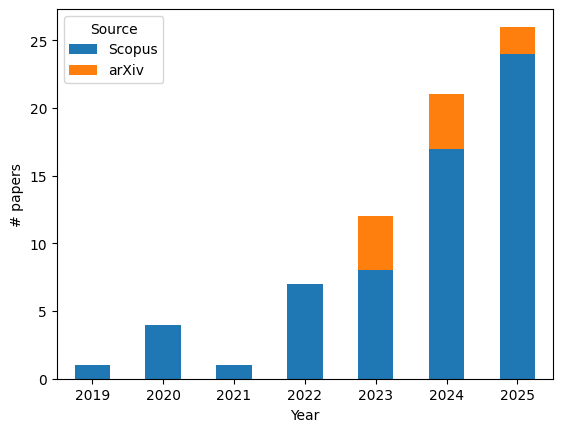

In [25]:
counts.plot(
    kind='bar',
    stacked=True,
    rot=0,
    ylabel="# papers"
)

In [14]:
# Novelty

df.topic.value_counts().sort_index()

topic
[Dataset]                        1
[Dataset, Evaluation]            1
[Evaluation]                     5
[Model]                         54
[Model, Dataset]                 7
[Model, Dataset, Evaluation]     3
[Model, Evaluation]              1
Name: count, dtype: int64

### MODEL

In [6]:
df_model = df[df.topic.apply(lambda x: "Model" in x)]

Text(0, 0.5, 'ML model')

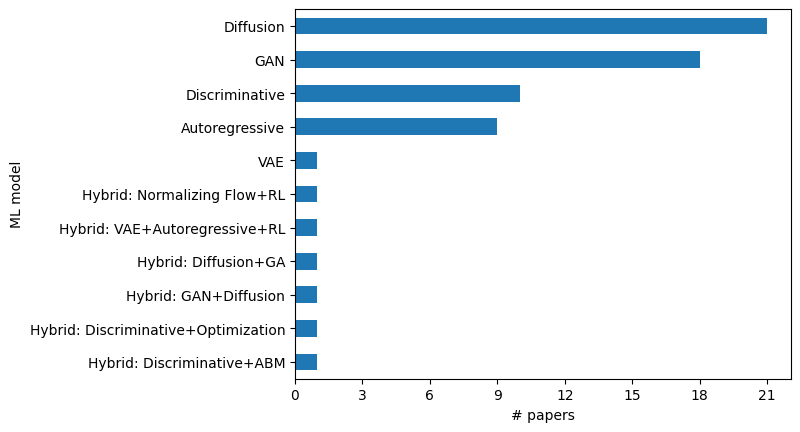

In [27]:
ax = df_model["Core Generative Paradigm"].value_counts(ascending=True).plot(kind="barh")
# ax.grid(axis="x")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("# papers")
ax.set_ylabel("ML model")


#### Discriminative vs Generative

In [ ]:
df_model["Model Group"] = df_model["Core Generative Paradigm"].apply(lambda x: "Discriminative" if "Discriminative" in x else "Generative")
df_model["Model Group"].value_counts()

Model Group
Generative        53
Discriminative    12
Name: count, dtype: int64

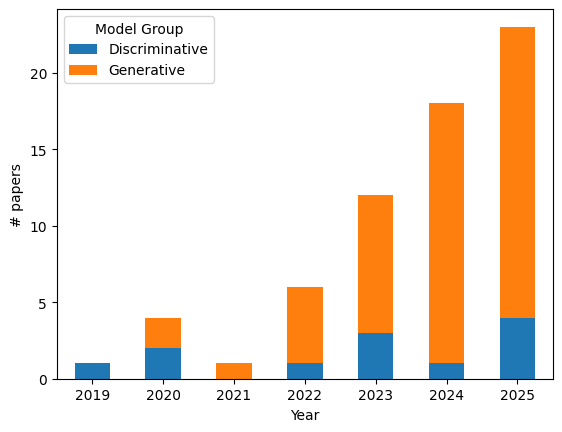

In [18]:
group_counts = df_model.groupby(['Year', 'Model Group']).size().unstack(fill_value=0)
group_counts = group_counts.sort_index()
group_counts

ax = group_counts.plot(
    kind='bar',
    stacked=True,
    rot=0,
    ylabel="# papers"
)
# ax.grid(axis="y")

#### Discriminative Hybrid vs Generative Hybrid

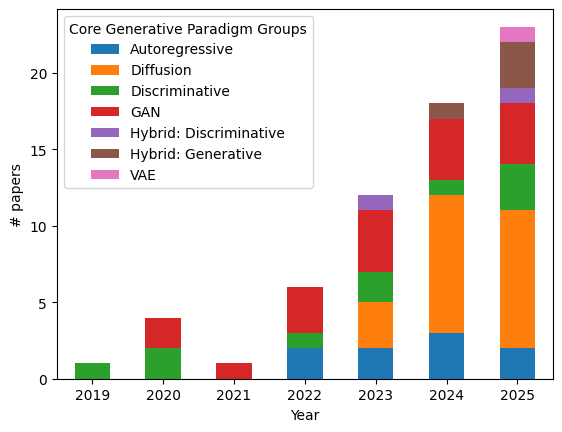

In [7]:
df_model["Core Generative Paradigm Groups"] = \
df_model["Core Generative Paradigm"].apply(lambda x: 
    "Hybrid: Discriminative" if ("Hybrid" in x and "Discriminative" in x) else 
    (
        "Hybrid: Generative" if "Hybrid" in x else x
    )
)

model_counts = df_model.groupby(['Year', 'Core Generative Paradigm Groups']).size().unstack(fill_value=0)
model_counts = model_counts.sort_index()

ax = model_counts.plot(
    kind='bar',
    stacked=True,
    rot=0,
    ylabel="# papers"
)

In [11]:
df_model.columns

Index(['topic', 'Detailed GP', 'Title', 'Year', 'Source', 'Unnamed: 5',
       'Pre processing outside generative model', 'Core Generative Paradigm',
       'Dataset', 'Unnamed: 9', 'Conditioning Regimes',
       'Neural Input (modality: semantics)', 'Neural Input Modality',
       'Neural Input elements', 'Neural Output (modality)',
       'Post processing outside generative model', 'Ultimate Output semantics',
       'Generalizability', 'User Studies', 'AF: undefined', 'AF: similarity',
       'AF: instruction-following', 'AF: Normative compliance',
       'AF: Intrinsic', 'Compound Metrics', 'Ablation study (none if empty)',
       'Core Generative Paradigm Groups'],
      dtype='str')

In [12]:
# color_map = {
#     'GAN': '#1f77b4',
#     'Diffusion': '#ff7f0e',
#     'VAE': '#2ca02c',
#     'Unspecified': '#999999'
# }

# colors = [color_map[col] for col in model_counts.columns]

# ax = model_counts.plot(
#     kind='bar',
#     stacked=True,
#     rot=0,
#     ylabel="# papers",
#     color=colors
)

SyntaxError: unmatched ')' (2252071439.py, line 16)

### POST PROCESSING

<Axes: xlabel='# papers', ylabel='Post-processing technique'>

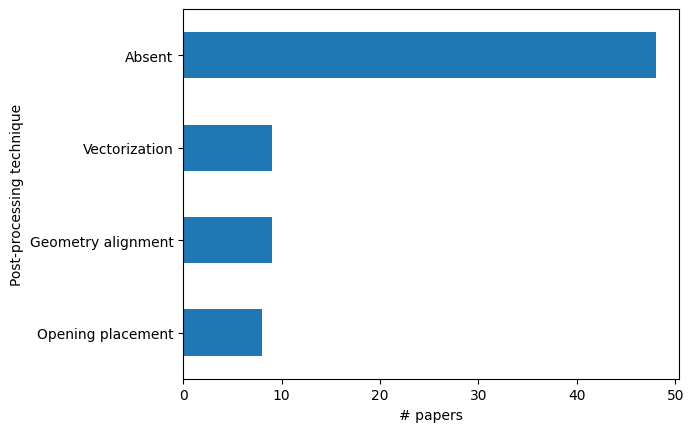

In [20]:
df_model["postprocessing"] = df_model["Post processing outside generative model"].apply(lambda x: x.split(", "))
df_model["postprocessing"].explode().value_counts(ascending=True).plot(kind="barh", xlabel="# papers", ylabel="Post-processing technique")

### PRE PROCESSING

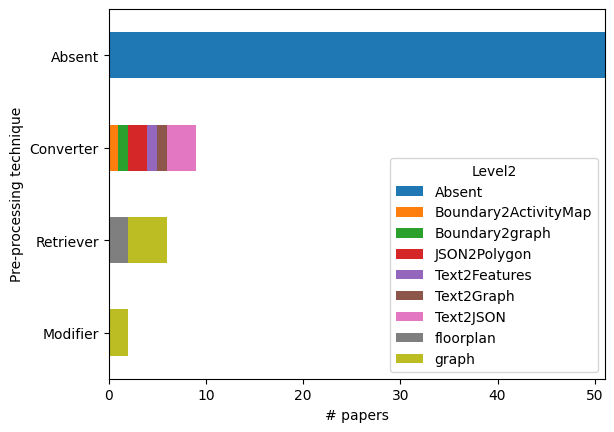

In [21]:
# df_model["preprocessing"] = df_model["Pre processing outside generative model"].apply(lambda x: x.split(", "))
# df_model["preprocessing"].explode().value_counts(ascending=True).plot(kind="pie")

two_level_barh(df_model, "Pre processing outside generative model", xlabel="# papers", ylabel="Pre-processing technique")

In [ ]:
///

### CONDITIONING INPUTS

In [28]:
df_model["input"] = df_model["Neural Input (modality: semantics)"].apply(lambda x: set(x.split(", ")))
df_model["input_modality"] = df_model["input"].apply(lambda x: set(i.split(": ")[0] for i in x))
df_model["input_semantics"] = df_model["input"].apply(lambda x: set(i.split(": ")[1] for i in x if i != "Absent"))


<Axes: ylabel='input_modality'>

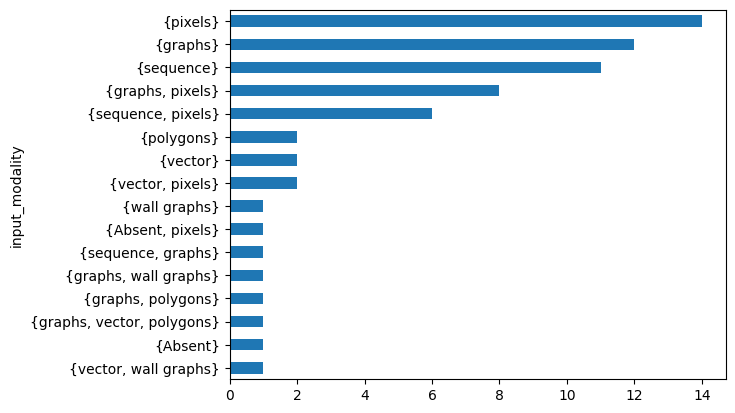

In [29]:
df_model["input_modality"].value_counts(ascending=True).plot(kind="barh")

<Axes: ylabel='input_semantics'>

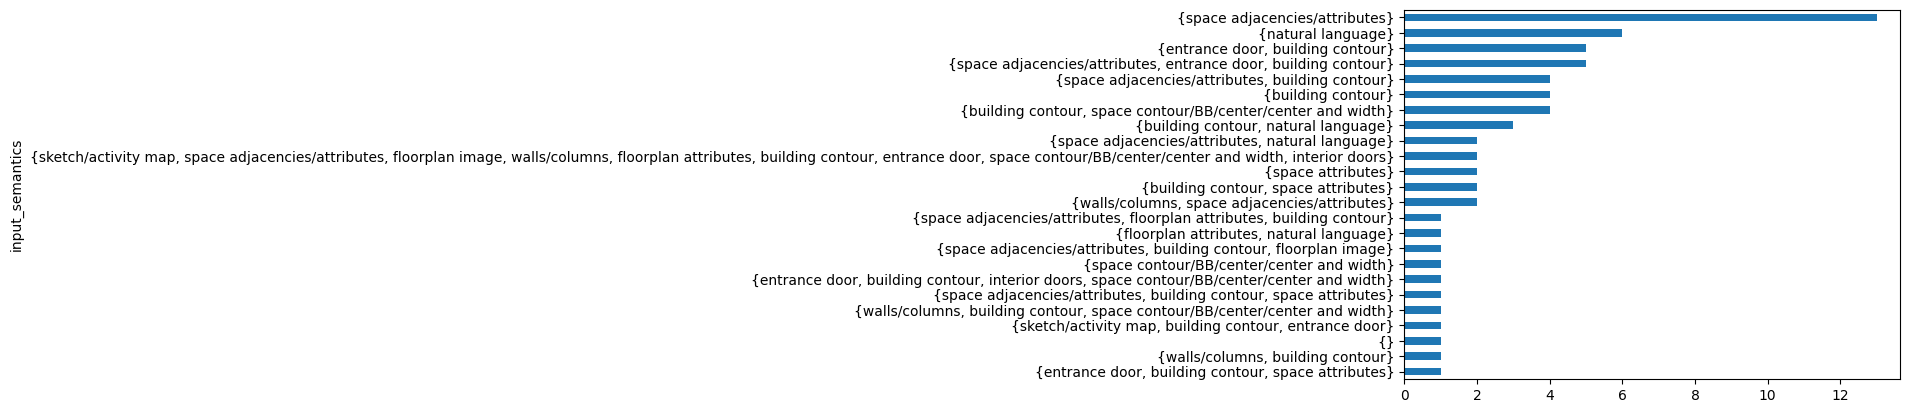

In [30]:
df_model["input_semantics"].value_counts(ascending=True).plot(kind="barh")

#### unqiue values

<Axes: xlabel='# papers', ylabel='Input -- modality: semantics'>

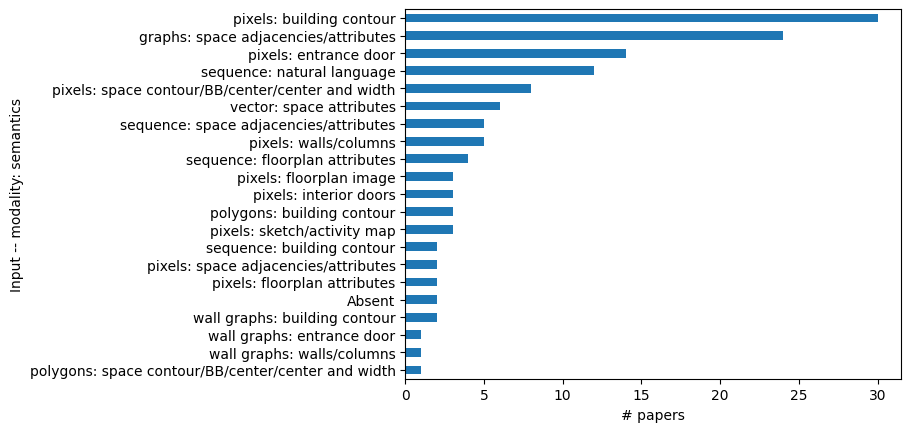

In [31]:
# redundant

df_model["input"] = df_model["Neural Input (modality: semantics)"].apply(lambda x: set(x.split(", ")))
df_model["input"].explode().value_counts(ascending=True).plot(kind="barh", xlabel="# papers", ylabel="Input -- modality: semantics")

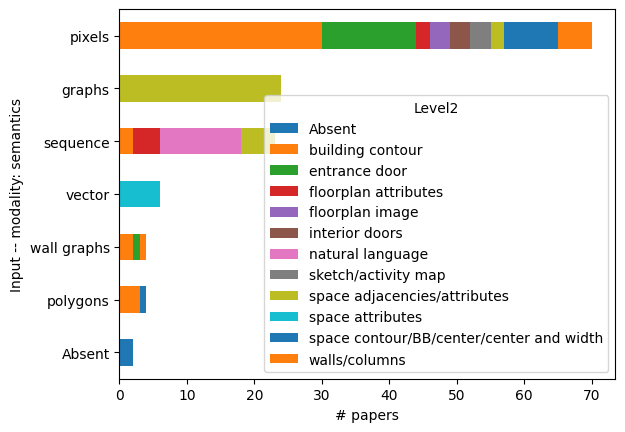

In [32]:
# replace with cooccurrence matrix or Sankey diagram (the last one!)

two_level_barh(df_model, "Neural Input (modality: semantics)", xlabel="# papers", ylabel="Input -- modality: semantics")

In [33]:
levels = df_model["input"].explode().str.split(':', n=1, expand=True)
levels.columns = ['level1', 'level2']

# Clean whitespace
levels = levels.apply(lambda col: col.str.strip())

# Count co-occurrences
counts = (
    levels
    .groupby(['level1', 'level2'])
    .size()
    .reset_index(name='count')
)

# Export
counts.to_csv("cooccurrence.csv", index=False)

print(counts)

         level1                                    level2  count
0        graphs              space adjacencies/attributes     24
1        pixels                          building contour     30
2        pixels                             entrance door     14
3        pixels                      floorplan attributes      2
4        pixels                           floorplan image      3
5        pixels                            interior doors      3
6        pixels                       sketch/activity map      3
7        pixels              space adjacencies/attributes      2
8        pixels  space contour/BB/center/center and width      8
9        pixels                             walls/columns      5
10     polygons                          building contour      3
11     polygons  space contour/BB/center/center and width      1
12     sequence                          building contour      2
13     sequence                      floorplan attributes      4
14     sequence          

In [16]:

df_coocurence = pd.read_csv("cooccurrence.csv")
df_coocurence

,level1,level2,count
0,graphs,space adjacencies/attributes,24
1,pixels,building contour,30
2,pixels,columns,1
3,pixels,entrance door,14
4,pixels,floorplan attributes,2
5,pixels,floorplan image,3
6,pixels,interior doors,3
7,pixels,sketch/activity map,3
8,pixels,space adjacencies/attributes,2
9,pixels,space contour/BB/center/center and width,8


In [7]:
import pandas as pd
import plotly.graph_objects as go

df_coocurence = pd.read_csv("cooccurrence.csv")

# Keep only needed columns
df_coocurence = df_coocurence[["level1", "level2", "count"]]

# Optional: remove tiny flows if diagram is too crowded
# df = df[df["Count"] >= 2]

sources = df_coocurence["level1"].astype(str)
targets = df_coocurence["level2"].astype(str)
values = df_coocurence["count"]

# Create unique node list
nodes = pd.Index(pd.concat([sources, targets]).unique())

# Map labels to numeric IDs
source_ids = sources.map(nodes.get_loc)
target_ids = targets.map(nodes.get_loc)

fig = go.Figure(data=[go.Sankey(
    node=dict(
        label=nodes.tolist(),
        pad=15,
        thickness=18
    ),
    link=dict(
        source=source_ids,
        target=target_ids,
        value=values
    )
)])

fig.update_layout(
    title_text="Modality → Semantics",
    font_size=16,
    width=1200,
    height=800
)

# fig.show()

#### combinations

In [28]:
# modalities

# semantics

### OUTPUT MODALITY

<Axes: xlabel='# papers', ylabel='Output modality'>

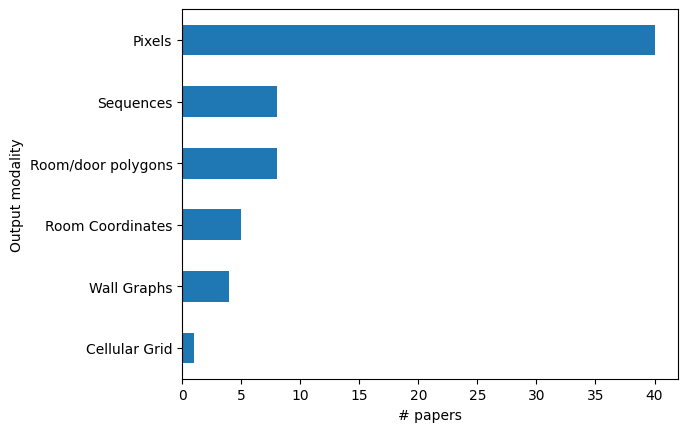

In [36]:
# ready to comment out

df_model["output_modality"] = df_model["Neural Output (modality)"].apply(lambda x: x.split(", "))
df_model["output_modality"].explode().value_counts(ascending=True).plot(kind="barh", xlabel="# papers", ylabel="Output modality")

# df_model["output_modality"].value_counts(ascending=True).plot(kind="barh", xlabel="# papers", ylabel="Output modality")


### OUTPUT SEMANTICS

<Axes: xlabel='# papers', ylabel='Output modality'>

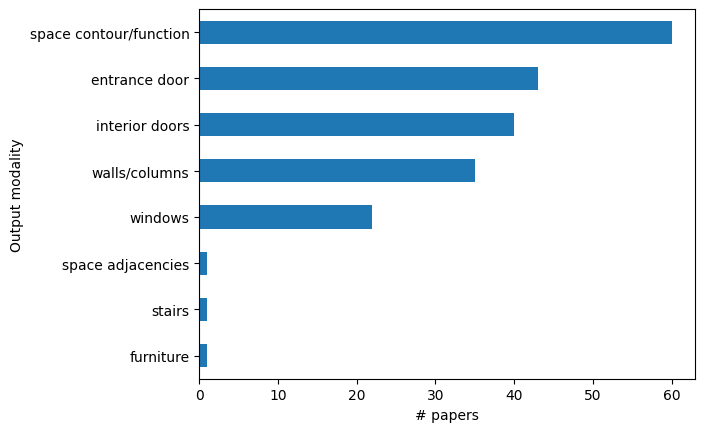

In [37]:
# ready to comment out

df_model["output_semantics"] = df_model["Ultimate Output semantics"].apply(lambda x: set(x.split(", ")))
df_model["output_semantics"].explode().value_counts(ascending=True).plot(kind="barh", xlabel="# papers", ylabel="Output modality")

<Axes: ylabel='output_semantics'>

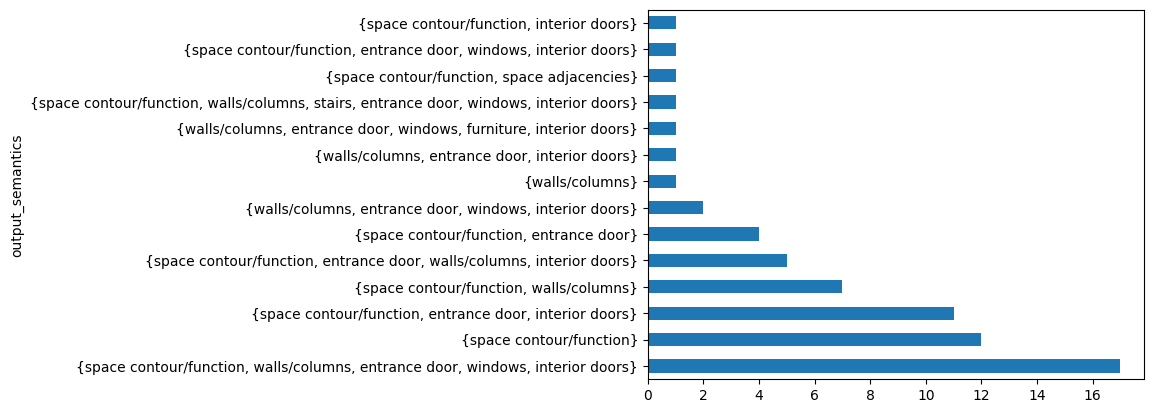

In [38]:
df_model["output_semantics"].value_counts().plot(kind="barh")

In [53]:
df_model["output_semantics"]

0                                space contour/function
1                                         walls/columns
2     entrance door + interior doors + space contour...
3                space contour/function + walls/columns
4     entrance door + interior doors + space contour...
                            ...                        
60    entrance door + interior doors + space contour...
61    entrance door + interior doors + space contour...
62    entrance door + interior doors + space contour...
63    entrance door + interior doors + space contour...
64              interior doors + space contour/function
Name: output_semantics, Length: 65, dtype: str

In [ ]:
df_model

### INPUT --> OUTPUT

#### MODALITY --> MODALITY

In [ ]:
# combinations --> combinations

#### SEMANTICS --> SEMANTICS

In [ ]:
# combinations --> combinations

In [32]:
df_model['input_semantics'].apply(lambda x: tuple(sorted(x)))

0     (building contour, entrance door, space adjace...
1     (building contour, space contour/BB/center/cen...
2     (building contour, entrance door, space adjace...
3                 (space adjacencies/attributes, walls)
4                  (building contour, space attributes)
                            ...                        
60                    (building contour, entrance door)
61                      (space adjacencies/attributes,)
62                  (floorplan class, natural language)
63    (attributes, building contour, space adjacenci...
64                    (building contour, entrance door)
Name: input_semantics, Length: 65, dtype: object

In [33]:
df_model['output_semantics'].apply(lambda x: tuple(sorted(x)))

0                          (room function and contour,)
1                                              (walls,)
2     (entrance door, interior doors, room function ...
3                    (room function and contour, walls)
4     (entrance door, interior doors, room function ...
                            ...                        
60    (entrance door, interior doors, room function ...
61    (entrance door, interior doors, room function ...
62    (entrance door, interior doors, room function ...
63    (entrance door, interior doors, room function ...
64          (interior doors, room function and contour)
Name: output_semantics, Length: 65, dtype: object

In [40]:
def set_to_label(x):
    return " + ".join(sorted(x)) if len(x) > 0 else "empty"

matrix = pd.crosstab(
    df_model['input_semantics'].apply(set_to_label),
    df_model['output_semantics'].apply(set_to_label),
)

matrix 

output_semantics,entrance door + furniture + interior doors + walls/columns + windows,entrance door + interior doors + space contour/function,entrance door + interior doors + space contour/function + stairs + walls/columns + windows,entrance door + interior doors + space contour/function + walls/columns,entrance door + interior doors + space contour/function + walls/columns + windows,entrance door + interior doors + space contour/function + windows,entrance door + interior doors + walls/columns,entrance door + interior doors + walls/columns + windows,entrance door + space contour/function,interior doors + space contour/function,space adjacencies + space contour/function,space contour/function,space contour/function + walls/columns,walls/columns
input_semantics,,,,,,,,,,,,,,
building contour,1,1,0,0,0,0,0,0,0,0,0,1,1,0
building contour + entrance door,0,0,0,1,2,0,0,0,0,1,0,0,1,0
building contour + entrance door + floorplan attributes + floorplan image + interior doors + sketch/activity map + space adjacencies/attributes + space contour/BB/center/center and width + walls/columns,0,0,0,0,2,0,0,0,0,0,0,0,0,0
building contour + entrance door + interior doors + space contour/BB/center/center and width,0,0,0,1,0,0,0,0,0,0,0,0,0,0
building contour + entrance door + sketch/activity map,0,0,0,1,0,0,0,0,0,0,0,0,0,0
building contour + entrance door + space adjacencies/attributes,0,0,0,0,3,0,0,0,1,0,0,1,0,0
building contour + entrance door + space attributes,0,0,0,0,1,0,0,0,0,0,0,0,0,0
building contour + floorplan attributes + space adjacencies/attributes,0,0,0,0,1,0,0,0,0,0,0,0,0,0
building contour + floorplan image + space adjacencies/attributes,0,0,0,1,0,0,0,0,0,0,0,0,0,0


In [41]:
df_model['input_semantics'] = df_model['input_semantics'].apply(set_to_label)
df_model['output_semantics']= df_model['output_semantics'].apply(set_to_label)

# cooc = (
#     df
#     .groupby(['input_semantics', 'output_semantics'])
#     .size()
#     .reset_index(name='Count')
# )

# cooc

In [51]:
df_model.columns

Index(['topic', 'Detailed GP', 'Title', 'Year', 'Source', 'Unnamed: 5',
       'Pre processing outside generative model', 'Core Generative Paradigm',
       'Dataset', 'Unnamed: 9', 'Conditioning Regimes',
       'Neural Input (modality: semantics)', 'Neural Input Modality',
       'Neural Input elements', 'Neural Output (modality)',
       'Post processing outside generative model', 'Ultimate Output semantics',
       'Generalizability', 'User Studies', 'AF: undefined', 'AF: similarity',
       'AF: instruction-following', 'AF: Normative compliance',
       'AF: Intrinsic', 'Compound Metrics', 'Ablation study (none if empty)',
       'input', 'input_modality', 'input_semantics',
       'M_Neural Input (modality: semantics)', 'output_modality',
       'output_semantics'],
      dtype='str')

In [36]:
df_model['input_semantics']

0     building contour + entrance door + space adjac...
1     building contour + space contour/BB/center/cen...
2     building contour + entrance door + space adjac...
3                  space adjacencies/attributes + walls
4                   building contour + space attributes
                            ...                        
60                     building contour + entrance door
61                         space adjacencies/attributes
62                   floorplan class + natural language
63    attributes + building contour + space adjacenc...
64                     building contour + entrance door
Name: input_semantics, Length: 65, dtype: str

In [37]:
df_model['output_semantics']

0                             room function and contour
1                                                 walls
2     entrance door + interior doors + room function...
3                     room function and contour + walls
4     entrance door + interior doors + room function...
                            ...                        
60    entrance door + interior doors + room function...
61    entrance door + interior doors + room function...
62    entrance door + interior doors + room function...
63    entrance door + interior doors + room function...
64           interior doors + room function and contour
Name: output_semantics, Length: 65, dtype: str

In [42]:
cooc = (
    df_model
    .groupby(['input_semantics', 'output_semantics'])
    .size()
    .reset_index(name='Count')
).sort_values("Count", ascending=False)

cooc.to_csv("cooc.csv")

In [47]:
pd.DataFrame(cooc["output_semantics"].value_counts())

,count
output_semantics,
entrance door + interior doors + space contour/function + walls/columns + windows,10
space contour/function,7
entrance door + interior doors + space contour/function,6
space contour/function + walls/columns,6
entrance door + interior doors + space contour/function + walls/columns,5
entrance door + space contour/function,3
entrance door + interior doors + walls/columns + windows,2
interior doors + space contour/function,1
entrance door + furniture + interior doors + walls/columns + windows,1


In [46]:
cooc["input_semantics"].value_counts()

input_semantics
space adjacencies/attributes                                                                                                                                                                                  5
natural language                                                                                                                                                                                              5
building contour + entrance door                                                                                                                                                                              4
building contour                                                                                                                                                                                              4
building contour + entrance door + space adjacencies/attributes                                                                                         

In [54]:
import pandas as pd
import plotly.graph_objects as go

df_cooc = pd.read_csv("cooc.csv")

# Keep only needed columns
df_cooc = df_cooc[["input_semantics", "output_semantics", "Count"]]

# Optional: remove tiny flows if diagram is too crowded
# df = df[df["Count"] >= 2]

sources = df_cooc["input_semantics"].astype(str)
targets = df_cooc["output_semantics"].astype(str)
values = df_cooc["Count"]

# Create unique node list
nodes = pd.Index(pd.concat([sources, targets]).unique())

# Map labels to numeric IDs
source_ids = sources.map(nodes.get_loc)
target_ids = targets.map(nodes.get_loc)

fig = go.Figure(data=[go.Sankey(
    node=dict(
        label=nodes.tolist(),
        pad=15,
        thickness=18
    ),
    link=dict(
        source=source_ids,
        target=target_ids,
        value=values
    )
)])

fig.update_layout(
    title_text="Input semantics → Output semantics",
    font_size=10,
    width=1200,
    height=800
)

# fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'link': {'source': {'bdata': 'AAABAgMEBQYHAAgJCgoBAQsMBAQKBAoNCA4GDwgQERITAhQUBxUWFgcHBwAAFw==',
                                  'dtype': 'i1'},
                       'target': {'bdata': 'GBkaGhoaGxwZGhgZGBkZHB0dHhsbHR8YGxoaHSAaISIbIxkaJCUZHRwaGCEbGA==',
                                  'dtype': 'i1'},
                       'value': {'bdata': 'BQQDAwICAgICAgICAQEBAQEBAQEBAQEBAQEBAQEBAQEBAQEBAQEBAQEBAQEBAQ==',
                                 'dtype': 'i1'}},
              'node': {'label': [space adjacencies/attributes, building contour +
                                 entrance door + space adjacencies/attributes,
                                 building contour + space contour/BB/center/center
                                 and width, building contour + entrance door +
                                 floorplan attributes + floorplan image + interior
                                 doors + sketch/activity map + space
                                 adjacencies/attributes + space
                                 contour/BB/center/center and width +
                                 walls/columns, building contour + entrance door,
                                 space adjacencies/attributes + walls/columns,
                                 building contour + natural language, natural
                                 language, building contour + space
                                 adjacencies/attributes, space attributes, building
                                 contour, building contour + entrance door +
                                 sketch/activity map, building contour + entrance
                                 door + interior doors + space
                                 contour/BB/center/center and width, building
                                 contour + space adjacencies/attributes + space
                                 attributes, building contour + entrance door +
                                 space attributes, building contour + floorplan
                                 image + space adjacencies/attributes, building
                                 contour + floorplan attributes + space
                                 adjacencies/attributes, empty, building contour +
                                 walls/columns, building contour + space
                                 contour/BB/center/center and width +
                                 walls/columns, building contour + space
                                 attributes, floorplan attributes + natural
                                 language, natural language + space
                                 adjacencies/attributes, space
                                 contour/BB/center/center and width, entrance door
                                 + interior doors + space contour/function, space
                                 contour/function, entrance door + interior doors +
                                 space contour/function + walls/columns + windows,
                                 space contour/function + walls/columns, entrance
                                 door + space contour/function, entrance door +
                                 interior doors + space contour/function +
                                 walls/columns, interior doors + space
                                 contour/function, entrance door + furniture +
                                 interior doors + walls/columns + windows, space
                                 adjacencies + space contour/function, entrance
                                 door + interior doors + walls/columns + windows,
                                 entrance door + interior doors + walls/columns,
                                 walls/columns, entrance door + interior doors +
                                 space contour/function + stairs + walls/columns +
                                 windows, entrance door + interior doors + space
                       

In [55]:
df_cooc["output_semantics"].value_counts()

output_semantics
entrance door + interior doors + space contour/function + walls/columns + windows             10
space contour/function                                                                         7
entrance door + interior doors + space contour/function                                        6
space contour/function + walls/columns                                                         6
entrance door + interior doors + space contour/function + walls/columns                        5
entrance door + space contour/function                                                         3
entrance door + interior doors + walls/columns + windows                                       2
interior doors + space contour/function                                                        1
entrance door + furniture + interior doors + walls/columns + windows                           1
space adjacencies + space contour/function                                                     1
entrance door

In [66]:
single_list = df_cooc["output_semantics"].value_counts()[df_cooc["output_semantics"].value_counts() < 2].index.to_list()
single_list

['interior doors + space contour/function',
 'entrance door + furniture + interior doors + walls/columns + windows',
 'space adjacencies + space contour/function',
 'entrance door + interior doors + walls/columns',
 'walls/columns',
 'entrance door + interior doors + space contour/function + stairs + walls/columns + windows',
 'entrance door + interior doors + space contour/function + windows']

In [56]:
df_cooc_1 = df_cooc[df_cooc["output_semantics"] == "entrance door + interior doors + space contour/function + walls/columns + windows"] 

sources = df_cooc_1["input_semantics"].astype(str)
targets = df_cooc_1["output_semantics"].astype(str)
values = df_cooc_1["Count"]

# Create unique node list
nodes = pd.Index(pd.concat([sources, targets]).unique())

# Map labels to numeric IDs
source_ids = sources.map(nodes.get_loc)
target_ids = targets.map(nodes.get_loc)

fig = go.Figure(data=[go.Sankey(
    node=dict(
        label=nodes.tolist(),
        pad=15,
        thickness=18
    ),
    link=dict(
        source=source_ids,
        target=target_ids,
        value=values
    )
)])

fig.update_layout(
     title_text="Input semantics → Output semantics",
    font_size=10,
    width=1200,
    height=800
)



ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'link': {'source': {'bdata': 'AAECAwQFBgcICQ==', 'dtype': 'i1'},
                       'target': {'bdata': 'CgoKCgoKCgoKCg==', 'dtype': 'i1'},
                       'value': {'bdata': 'AwMCAgIBAQEBAQ==', 'dtype': 'i1'}},
              'node': {'label': [building contour + entrance door + space
                                 adjacencies/attributes, building contour + space
                                 contour/BB/center/center and width, building
                                 contour + entrance door + floorplan attributes +
                                 floorplan image + interior doors + sketch/activity
                                 map + space adjacencies/attributes + space
                                 contour/BB/center/center and width +
                                 walls/columns, building contour + entrance door,
                                 space adjacencies/attributes, building contour +
                                 entrance door + space attributes, building contour
                                 + natural language, building contour + floorplan
                                 attributes + space adjacencies/attributes,
                                 building contour + space attributes, natural
                                 language, entrance door + interior doors + space
                                 contour/function + walls/columns + windows],
                       'pad': 15,
                       'thickness': 18},
              'type': 'sankey'}],
    'layout': {'font': {'size': 10},
               'height': 800,
               'template': '...',
               'title': {'text': 'Input semantics → Output semantics'},
               'width': 1200}
})

In [57]:
df_cooc_2 = df_cooc[df_cooc["output_semantics"] == "space contour/function"] 

sources = df_cooc_2["input_semantics"].astype(str)
targets = df_cooc_2["output_semantics"].astype(str)
values = df_cooc_2["Count"]

# Create unique node list
nodes = pd.Index(pd.concat([sources, targets]).unique())

# Map labels to numeric IDs
source_ids = sources.map(nodes.get_loc)
target_ids = targets.map(nodes.get_loc)

fig = go.Figure(data=[go.Sankey(
    node=dict(
        label=nodes.tolist(),
        pad=15,
        thickness=18
    ),
    link=dict(
        source=source_ids,
        target=target_ids,
        value=values
    )
)])

fig.update_layout(
     title_text="Input semantics → Output semantics",
    font_size=10,
    width=1200,
    height=800
)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'link': {'source': {'bdata': 'AAECAwQFBg==', 'dtype': 'i1'},
                       'target': {'bdata': 'BwcHBwcHBw==', 'dtype': 'i1'},
                       'value': {'bdata': 'BAICAQEBAQ==', 'dtype': 'i1'}},
              'node': {'label': [space adjacencies/attributes, natural language,
                                 space attributes, building contour, building
                                 contour + entrance door + space
                                 adjacencies/attributes, building contour + space
                                 attributes, natural language + space
                                 adjacencies/attributes, space contour/function],
                       'pad': 15,
                       'thickness': 18},
              'type': 'sankey'}],
    'layout': {'font': {'size': 10},
               'height': 800,
               'template': '...',
               'title': {'text': 'Input semantics → Output semantics'},
               'width': 1200}
})

In [67]:
df_cooc_3 = df_cooc[df_cooc["output_semantics"].isin(single_list)] 

sources = df_cooc_3["input_semantics"].astype(str)
targets = df_cooc_3["output_semantics"].astype(str)
values = df_cooc_3["Count"]

# Create unique node list
nodes = pd.Index(pd.concat([sources, targets]).unique())

# Map labels to numeric IDs
source_ids = sources.map(nodes.get_loc)
target_ids = targets.map(nodes.get_loc)

fig = go.Figure(data=[go.Sankey(
    node=dict(
        label=nodes.tolist(),
        pad=15,
        thickness=18
    ),
    link=dict(
        source=source_ids,
        target=target_ids,
        value=values
    )
)])

fig.update_layout(
     title_text="Input semantics → Output semantics",
    font_size=10,
    width=1200,
    height=800
)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'link': {'source': {'bdata': 'AAECAwQFBg==', 'dtype': 'i1'},
                       'target': {'bdata': 'BwgJCgsMDQ==', 'dtype': 'i1'},
                       'value': {'bdata': 'AQEBAQEBAQ==', 'dtype': 'i1'}},
              'node': {'label': [building contour + entrance door, building
                                 contour, building contour + space
                                 adjacencies/attributes, building contour +
                                 walls/columns, building contour + space
                                 contour/BB/center/center and width, natural
                                 language, floorplan attributes + natural language,
                                 interior doors + space contour/function, entrance
                                 door + furniture + interior doors + walls/columns
                                 + windows, space adjacencies + space
                                 contour/function, entrance door + interior doors +
                                 walls/columns, walls/columns, entrance door +
                                 interior doors + space contour/function + stairs +
                                 walls/columns + windows, entrance door + interior
                                 doors + space contour/function + windows],
                       'pad': 15,
                       'thickness': 18},
              'type': 'sankey'}],
    'layout': {'font': {'size': 10},
               'height': 800,
               'template': '...',
               'title': {'text': 'Input semantics → Output semantics'},
               'width': 1200}
})

### DATASET

In [44]:
df["dataset"] = df["Dataset"].apply(lambda x: x.split(", "))

dataset_exploded = df.explode("dataset")
dataset_exploded["dataset"].value_counts(ascending=True).plot(kind="barh", xlabel="# papers")

KeyError: 'Dataset'

<Axes: xlabel='# papers', ylabel='dataset_grouped'>

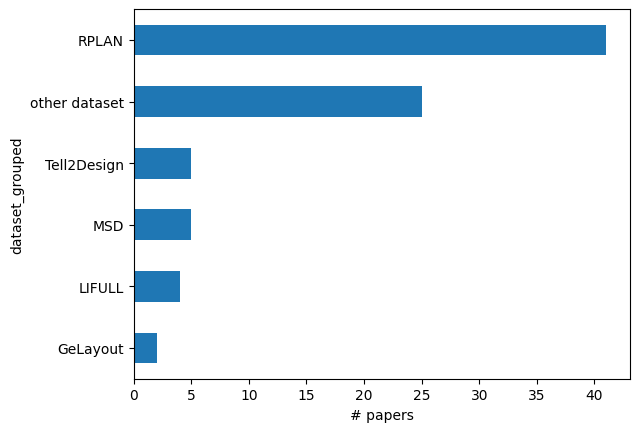

In [21]:
dataset_exploded["dataset_grouped"] = dataset_exploded.dataset.apply(lambda x: x if x in ["LIFULL", "RPLAN", "GeLayout", "MSD", "Tell2Design"] else "other dataset")
dataset_exploded["dataset_grouped"].value_counts(ascending=True).plot(kind="barh", xlabel="# papers")

In [22]:
unique_ds_list = [
    d for d in dataset_exploded["dataset"].unique() if d not in ["LIFULL", "RPLAN", "GeLayout", "MSD", "Tell2Design"]
]

unique_ds = pd.DataFrame(
    data=unique_ds_list, 
    columns=["dataset"]
).sort_values(by="dataset").reset_index(drop=True)

unique_ds.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
dataset,ArchiMetricsNet,Custom,DS2D,GreenPD,Huang and Zheng 2018,LLAMA,Liu Wu et al 2017,MRED-14,Multi-RP,NM-RPLAN,P-PLAN,PUBLICPLAN,ResPlan,Solar Decathlon,Tell2Floorplan,pseudo-floor-plan-12k


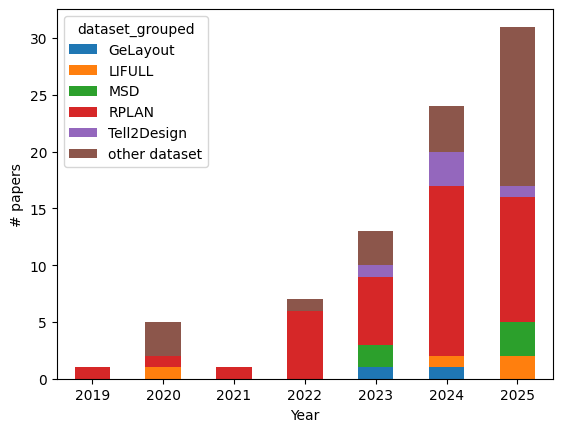

In [23]:
def merge_datasets(x):
    groups = ["LIFULL", "RPLAN", "GeLayout", "MSD", "Tell2Design"]
    return x if x in groups else "other dataset"

dataset_exploded["dataset_grouped"] = dataset_exploded["dataset"].apply(merge_datasets)

dataset_counts = (
    dataset_exploded
    .groupby(['Year', 'dataset_grouped'])
    .size()
    .unstack(fill_value=0)
)

ax = dataset_counts.plot(
    kind='bar',
    stacked=True,
    ylabel='# papers',
    # figsize=(12,6)
)
ax.tick_params(axis='x', rotation=0)

### GENERALIZABILITY

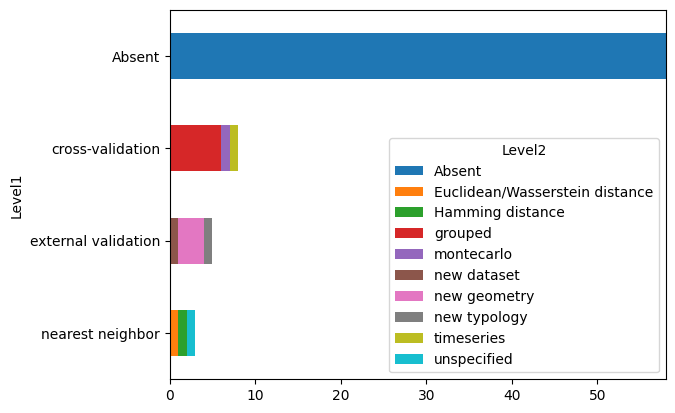

In [24]:
two_level_barh(df, "Generalizability")

# USER STUDIES

In [20]:
def plot_user_studies(df):
    df["user_studies"] = df["User Studies"].apply(lambda x: x.split(", "))
    pp_counts = df["user_studies"].explode().value_counts(ascending=True)
    
    cmap = plt.cm.tab20
    num_colors = len(pp_counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    pp_counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="User study type",
        color=colors,
    )

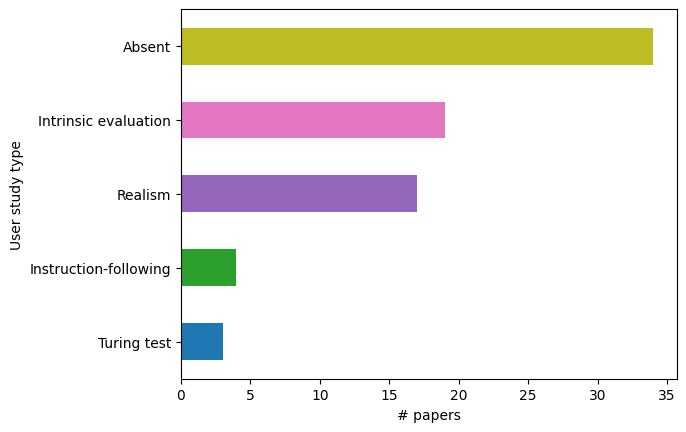

In [21]:
plot_user_studies(df)